# 01 · Tiền xử lý dữ liệu

**Đức** · WDI 2010–2024 · Mỗi hàng là một quốc gia–năm. Chạy từ đầu trước notebook 02.

## 1. Giới thiệu và mục tiêu xử lý dữ liệu

Loại nhóm tổng hợp, xử lý khoảng thiếu ngắn và chuẩn hóa 8 biến. Giữ các giá trị cực trị để phân tích, không tự xem chúng là lỗi.

In [1]:
from pathlib import Path
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import RobustScaler, StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "du_lieu").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook trong repo DBSCAN.")
    ROOT = ROOT.parent
RAW = ROOT / "du_lieu/du_lieu_tho"
CLEAN = ROOT / "du_lieu/du_lieu_sach"
SCALED = ROOT / "du_lieu/du_lieu_chuan_hoa"
FIG = ROOT / "Duc/bieu_do"
for folder in [CLEAN, SCALED, FIG]:
    folder.mkdir(parents=True, exist_ok=True)
KEYS = ["country", "year"]
dictionary = pd.read_csv(ROOT / "du_lieu/tu_dien_chi_tieu.csv")
features = dictionary.indicator.tolist()
names = dict(zip(features, ["GDP/người", "Tăng trưởng GDP", "Lạm phát", "Thất nghiệp",
                           "Thương mại/GDP", "Tích lũy vốn/GDP", "Đô thị hóa", "Chi tiêu CP/GDP"]))
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})

## 2. Thu thập dữ liệu World Bank WDI

Dùng snapshot đã tải sẵn. Kiểm tra checksum theo manifest; chỉ cho phép khác biệt xuống dòng LF/CRLF.

In [2]:
manifest = json.loads((RAW / "manifest.json").read_text(encoding="utf-8"))
for entry in manifest["files"]:
    raw_bytes = (RAW / entry["file"]).read_bytes()
    normal = raw_bytes.replace(b"\r\n", b"\n")
    hashes = {hashlib.sha256(raw_bytes).hexdigest(), hashlib.sha256(normal).hexdigest()}
    assert entry["sha256"] in hashes, entry["file"]
print(f"Đã kiểm tra {len(manifest['files'])} file nguồn; WDI source {manifest['source_id']}.")
display(dictionary[["indicator", "name_vi", "unit_vi"]])

Đã kiểm tra 19 file nguồn; WDI source 2.


,indicator,name_vi,unit_vi
0,NY.GDP.PCAP.KD,GDP bình quân đầu người,USD cố định năm 2015
1,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP,%/năm
2,FP.CPI.TOTL.ZG,Lạm phát giá tiêu dùng,%/năm
3,SL.UEM.TOTL.ZS,Thất nghiệp - ước tính mô hình ILO,% lực lượng lao động
4,NE.TRD.GNFS.ZS,Thương mại - xuất khẩu cộng nhập khẩu,% GDP
5,NE.GDI.TOTL.ZS,Tổng tích lũy vốn,% GDP
6,SP.URB.TOTL.IN.ZS,Dân số đô thị,% dân số
7,NE.CON.GOVT.ZS,Chi tiêu tiêu dùng cuối cùng của chính phủ,% GDP


## 3. Khám phá cấu trúc dữ liệu

In [3]:
raw = pd.read_csv(RAW / "wdi_2010_2024.csv")
long = pd.read_csv(RAW / "wdi_2010_2024_long.csv")
assert not raw.duplicated(KEYS).any()
assert not long.duplicated(KEYS + ["indicator"]).any()
wide_values = raw.set_index(KEYS)[features].sort_index()
long_values = long.pivot(index=KEYS, columns="indicator", values="value").sort_index()[features]
pd.testing.assert_frame_equal(wide_values, long_values, check_names=False, check_exact=True)
countries = json.loads((RAW / "nguon_api/countries.json").read_text(encoding="utf-8"))[1]
aggregate_flags = {r["id"]: int(r["region"]["id"] == "NA") for r in countries}
assert raw.country.map(aggregate_flags).equals(raw.is_aggregate)
print(f"Bảng rộng: {raw.shape}; bảng dài: {long.shape}.")
display(raw.groupby("is_aggregate").agg(entities=("country", "nunique"), rows=("country", "size")))

Bảng rộng: (3990, 12); bảng dài: (31920, 7).


,entities,rows
is_aggregate,,
0,217,3255
1,49,735


## 4. Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp

,missing,percent
NY.GDP.PCAP.KD,133,4.086022
NY.GDP.MKTP.KD.ZG,122,3.748080
FP.CPI.TOTL.ZG,483,14.838710
SL.UEM.TOTL.ZS,459,14.101382
NE.TRD.GNFS.ZS,534,16.405530
NE.GDI.TOTL.ZS,642,19.723502
SP.URB.TOTL.IN.ZS,0,0.000000
NE.CON.GOVT.ZS,628,19.293395


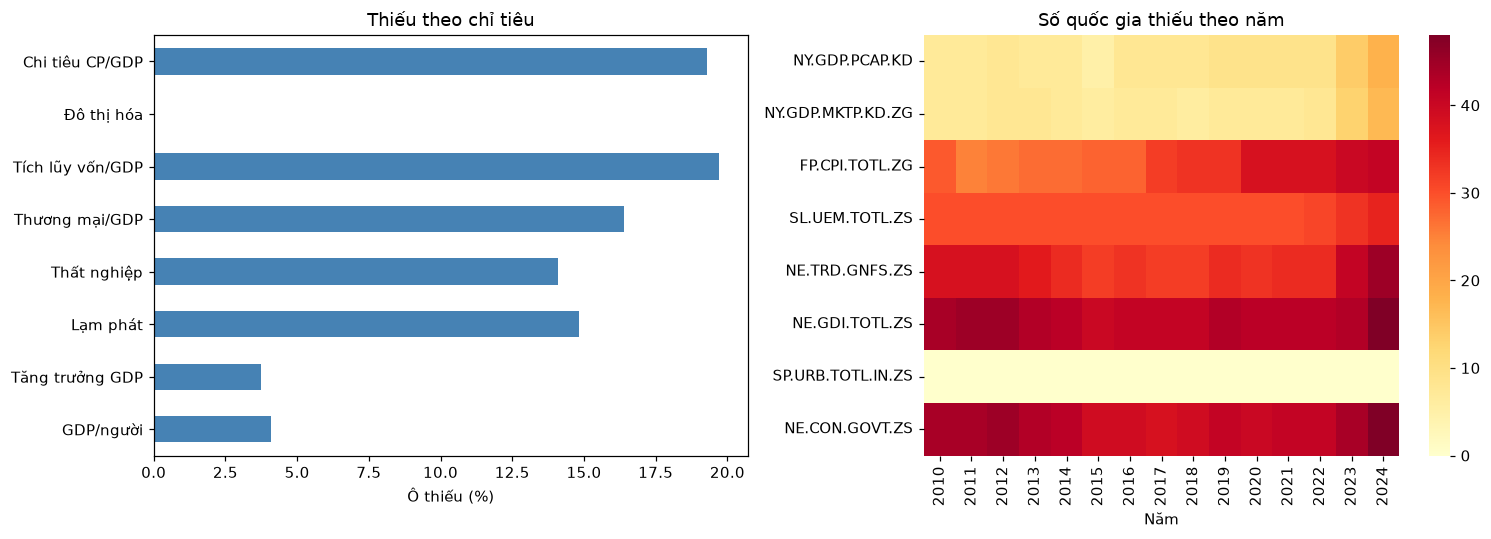

In [4]:
source = raw.loc[raw.is_aggregate == 0].sort_values(KEYS).reset_index(drop=True)
assert not source[KEYS].isna().any().any()
missing = source[features].isna().sum().to_frame("missing")
missing["percent"] = source[features].isna().mean() * 100
display(missing)
missing_year = source[features].isna().groupby(source.year).sum().T
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing.percent.rename(index=names).plot.barh(ax=axes[0], color="steelblue")
axes[0].set(xlabel="Ô thiếu (%)", ylabel="", title="Thiếu theo chỉ tiêu")
sns.heatmap(missing_year, ax=axes[1], cmap="YlOrRd", yticklabels=features)
axes[1].set(title="Số quốc gia thiếu theo năm", xlabel="Năm", ylabel="")
fig.tight_layout(); fig.savefig(FIG / "01_ty_le_thieu_theo_nam_va_chi_tieu.png"); plt.show()

## 5. Làm sạch dữ liệu

Chỉ nội suy khoảng trống **bên trong dài tối đa 2 năm**; chỉ điền biên khi toàn khoảng thiếu ở biên dài đúng 1 năm. Không điền một phần khoảng thiếu dài. Sau đó bỏ hàng vẫn thiếu biến.

In [5]:
def fill_short_gaps(values):
    result = values.copy()
    i = 0
    while i < len(values):
        if pd.notna(values.iloc[i]):
            i += 1
            continue
        end = i + 1
        while end < len(values) and pd.isna(values.iloc[end]):
            end += 1
        if i > 0 and end < len(values) and end - i <= 2:
            result.iloc[i:end] = np.linspace(values.iloc[i - 1], values.iloc[end], end - i + 2)[1:-1]
        elif end - i == 1:
            if i == 0 and end < len(values):
                result.iloc[i] = values.iloc[end]
            elif end == len(values) and i > 0:
                result.iloc[i] = values.iloc[i - 1]
        i = end
    return result

nan = np.nan
tests = [([1, nan, nan, 4], [1, 2, 3, 4]),
         ([1, nan, nan, nan, 5], [1, nan, nan, nan, 5]),
         ([nan, 2, 3, nan], [2, 2, 3, 3]),
         ([nan, nan, 3], [nan, nan, 3]), ([1, nan, nan], [1, nan, nan]),
         ([nan, nan], [nan, nan]), ([nan], [nan]), ([2], [2])]
for before, expected in tests:
    actual = fill_short_gaps(pd.Series(before, dtype=float))
    np.testing.assert_allclose(actual, expected, equal_nan=True)
print(f"Đạt {len(tests)} kiểm thử nội suy.")

Đạt 8 kiểm thử nội suy.


In [6]:
filled = source.copy()
for feature in features:
    filled[feature] = source.groupby("country")[feature].transform(fill_short_gaps)
imputed = source[features].isna() & filled[features].notna()
log_rows = []
for feature in features:
    rows = filled.loc[imputed[feature], KEYS + [feature]].copy()
    rows = rows.rename(columns={feature: "value"}).assign(indicator=feature)
    log_rows.append(rows)
imputation_log = pd.concat(log_rows, ignore_index=True)
clean = filled.dropna(subset=features).reset_index(drop=True)
assert np.isfinite(clean[features].to_numpy()).all()
assert clean.is_aggregate.eq(0).all() and not clean.duplicated(KEYS).any()
print(f"Đã điền {imputed.sum().sum()} ô; giữ {len(clean)} hàng, {clean.country.nunique()} nền kinh tế.")
display(clean.groupby("year").size().rename("n_samples").to_frame().T)

Đã điền 32 ô; giữ 2315 hàng, 162 nền kinh tế.


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n_samples,154,153,152,153,155,156,156,155,156,156,156,156,155,151,151


## 6. Phân tích khám phá dữ liệu EDA

,count,mean,std,min,25%,50%,75%,max
NY.GDP.PCAP.KD,2315.0,14905.208108,20207.336254,349.821172,1950.177179,5736.304496,19210.598265,110873.115269
NY.GDP.MKTP.KD.ZG,2315.0,3.185873,5.472796,-54.402093,1.419857,3.406873,5.459331,86.826748
FP.CPI.TOTL.ZG,2315.0,6.102477,18.874760,-6.601186,1.476280,3.220934,6.215814,557.201817
SL.UEM.TOTL.ZS,2315.0,7.554354,5.805371,0.100000,3.604000,5.615000,9.797000,34.007000
NE.TRD.GNFS.ZS,2315.0,89.450000,56.728509,0.000000,53.401051,76.966649,106.704783,442.620019
NE.GDI.TOTL.ZS,2315.0,24.551187,8.389720,-15.678444,19.576687,23.543670,28.073341,76.782325
SP.URB.TOTL.IN.ZS,2315.0,61.017388,21.963350,15.963428,42.680356,63.412726,78.372237,100.000000
NE.CON.GOVT.ZS,2315.0,16.598260,6.897662,0.000000,12.097790,16.122567,19.743792,103.163534


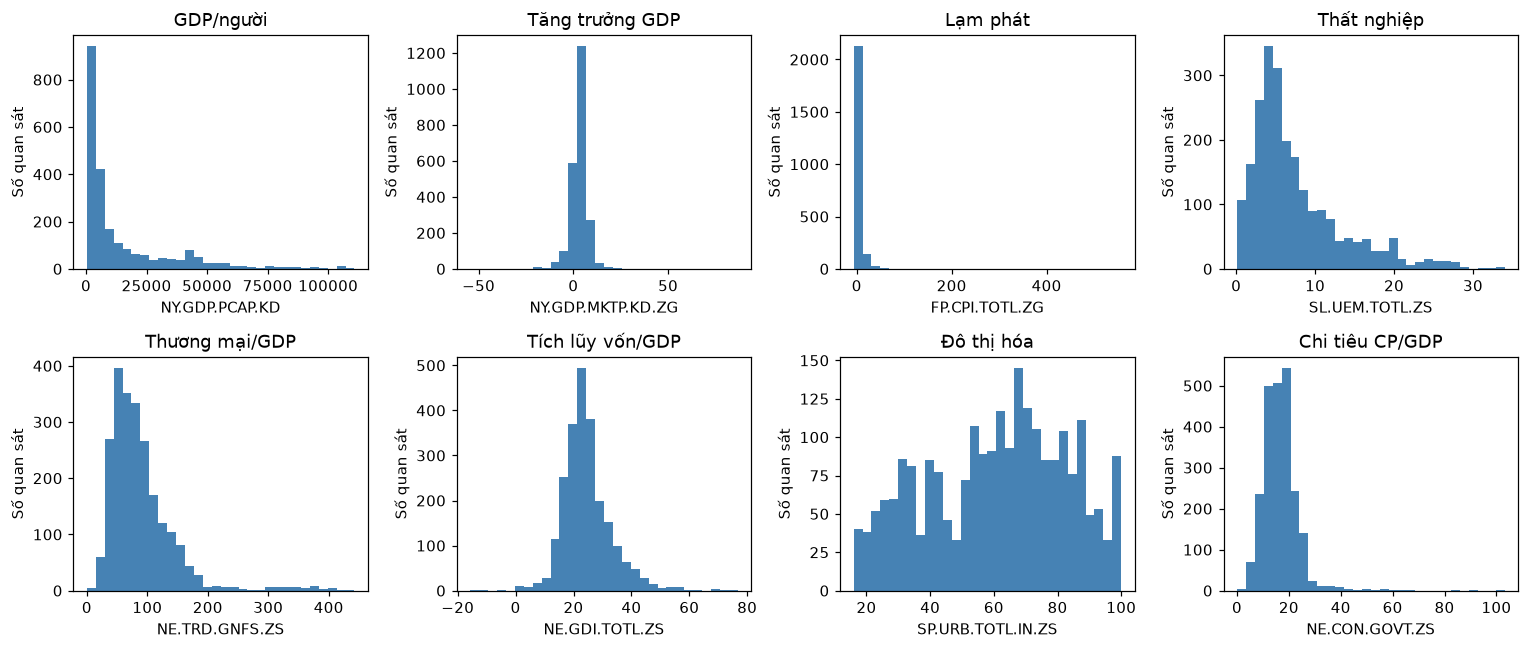

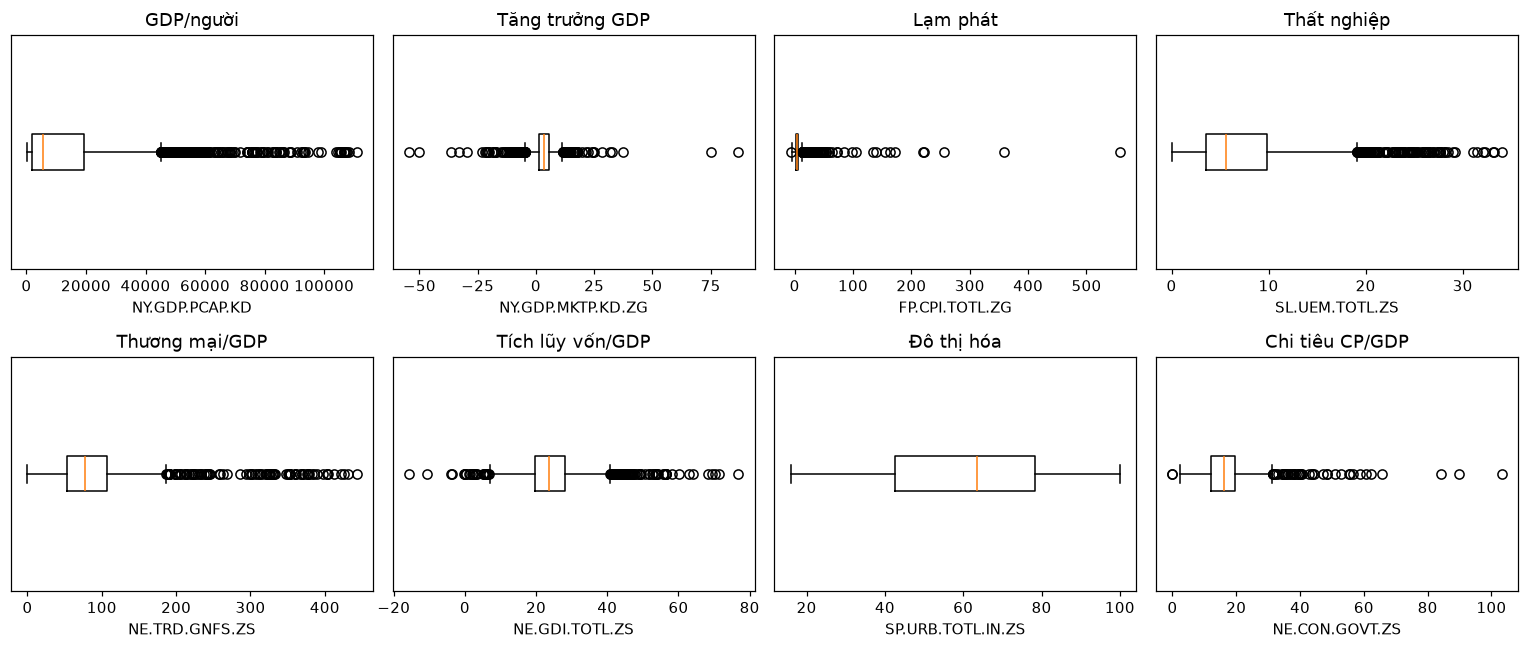

In [7]:
display(clean[features].describe().T)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, feature in zip(axes.flat, features):
    ax.hist(clean[feature], bins=30, color="steelblue")
    ax.set(title=names[feature], xlabel=feature, ylabel="Số quan sát")
fig.tight_layout(); fig.savefig(FIG / "02_phan_phoi_8_chi_tieu_goc.png"); plt.show()
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, feature in zip(axes.flat, features):
    ax.boxplot(clean[feature], orientation="horizontal")
    ax.set(title=names[feature], xlabel=feature, yticks=[])
fig.tight_layout(); fig.savefig(FIG / "03_boxplot_ngoai_lai_8_chi_tieu.png"); plt.show()

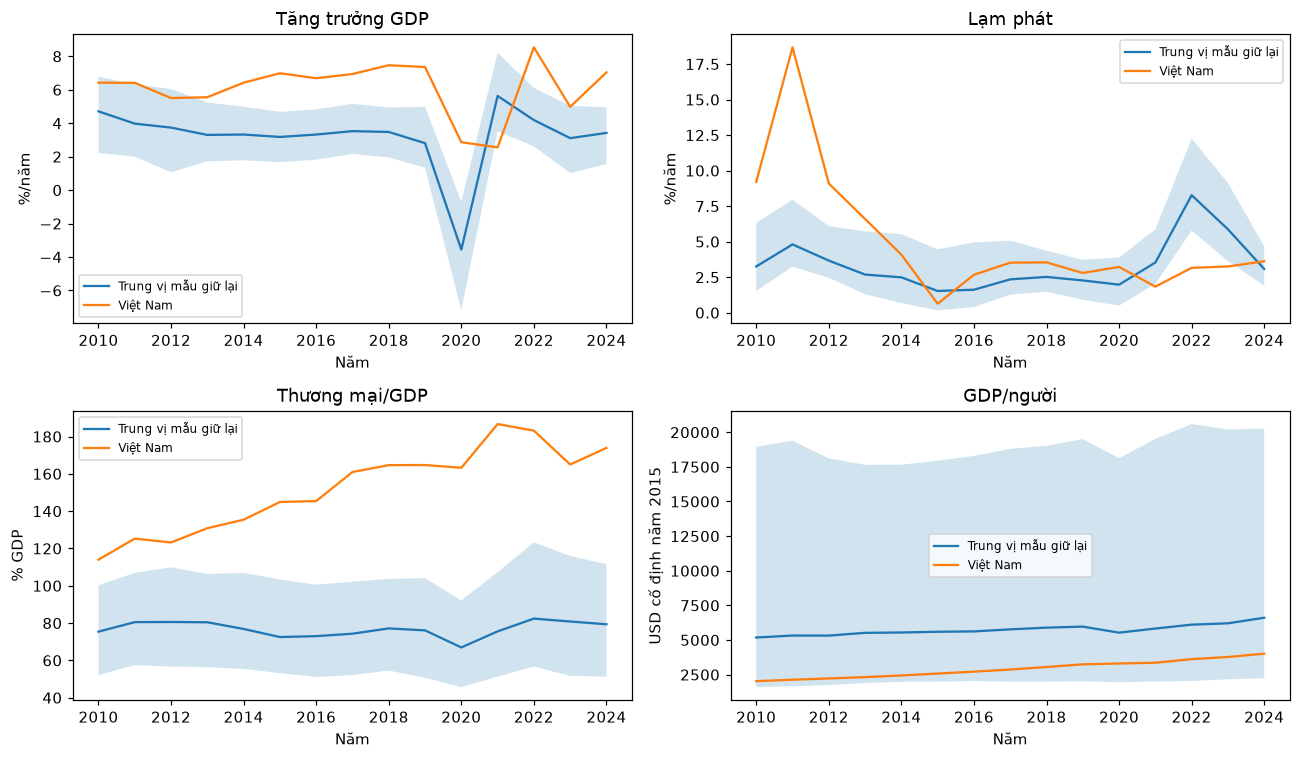

In [8]:
trend_features = [features[1], features[2], features[4], features[0]]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, feature in zip(axes.flat, trend_features):
    grouped = clean.groupby("year")[feature]
    median = grouped.median()
    vietnam = clean.loc[clean.country == "VNM"].set_index("year")[feature]
    ax.plot(median.index, median, label="Trung vị mẫu giữ lại")
    ax.fill_between(median.index, grouped.quantile(0.25), grouped.quantile(0.75), alpha=0.2)
    ax.plot(vietnam.index, vietnam, label="Việt Nam")
    ax.set(title=names[feature], xlabel="Năm", ylabel=dictionary.set_index("indicator").loc[feature, "unit_vi"])
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "04_xu_huong_vi_mo_2010_2024.png"); plt.show()

## 7. Phân tích tương quan giữa các biến

Giữ cả 8 biến vì chúng mô tả các khía cạnh khác nhau. Tương quan không chứng minh quan hệ nhân quả.

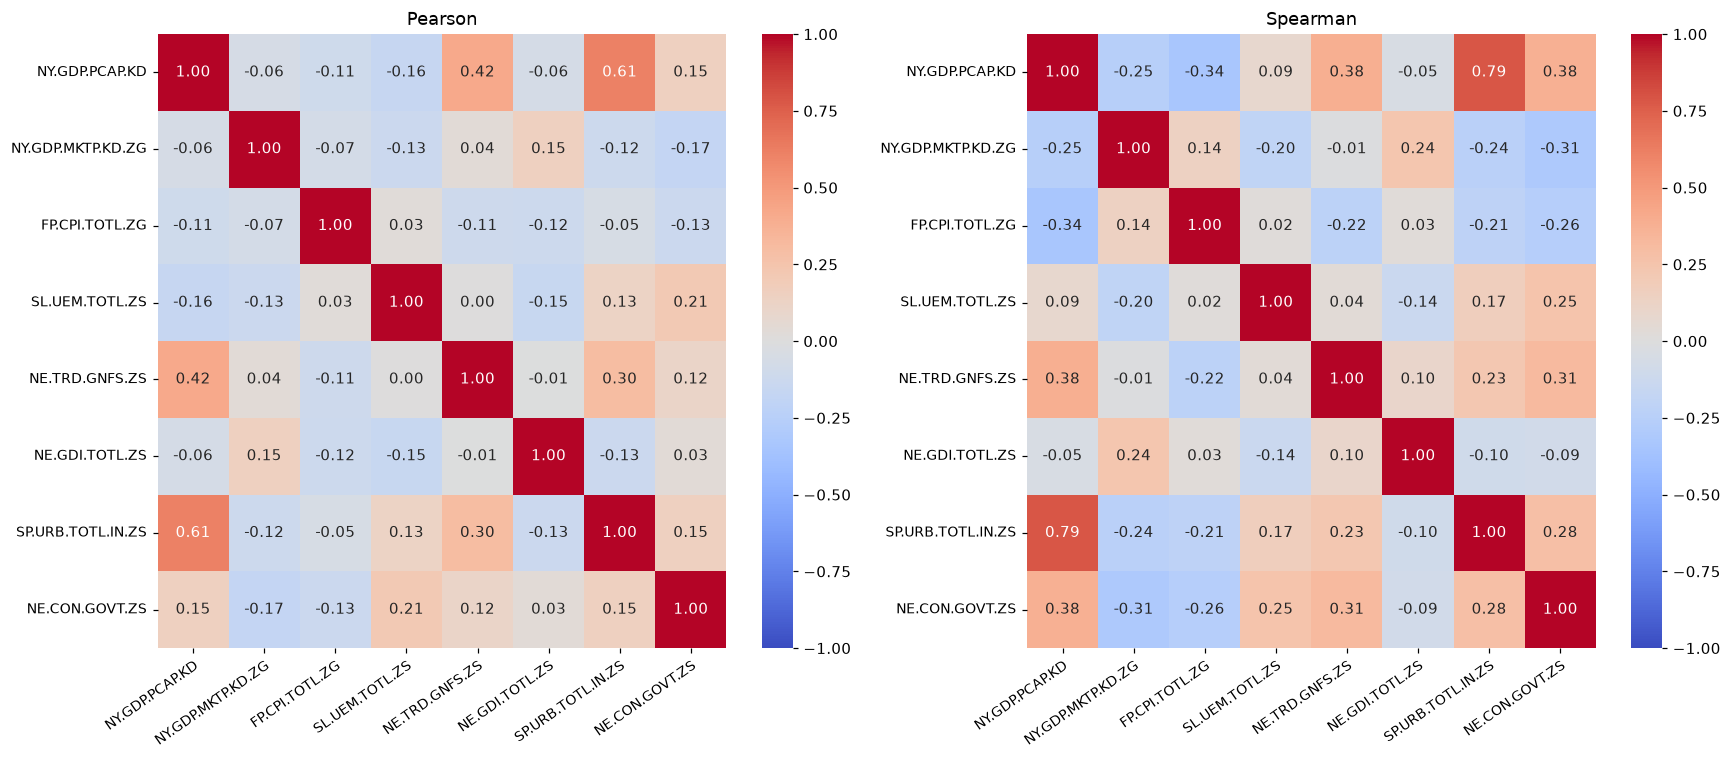

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, method in zip(axes, ["pearson", "spearman"]):
    correlation = clean[features].corr(method=method)
    sns.heatmap(correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax)
    ax.set_title(method.title())
    ax.set_xticklabels(features, rotation=35, ha="right", rotation_mode="anchor", fontsize=9)
    ax.set_yticklabels(features, rotation=0, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "05_ma_tran_tuong_quan.png"); plt.show()

## 8. Biến đổi và chuẩn hóa dữ liệu

Log1p cho 4 biến không âm lệch phải; signed-log cho lạm phát có thể âm. RobustScaler fit toàn panel: trung vị 0, IQR 1. Đây là xử lý hồi cứu, không dùng để đánh giá dự báo tương lai.

In [10]:
log_columns = [features[0], features[3], features[4], features[7]]
signed_columns = [features[2]]
transformed = clean[features].copy()
assert (transformed[log_columns] >= 0).all().all()
transformed[log_columns] = np.log1p(transformed[log_columns])
transformed[signed_columns] = np.sign(transformed[signed_columns]) * np.log1p(transformed[signed_columns].abs())
scaler = RobustScaler()
values = scaler.fit_transform(transformed)
scaled = clean[KEYS + ["country_name"]].copy()
scaled[features] = values
assert np.isfinite(values).all()
np.testing.assert_allclose(np.median(values, axis=0), 0, atol=1e-10)
np.testing.assert_allclose(np.percentile(values, 75, axis=0) - np.percentile(values, 25, axis=0), 1)
display(pd.DataFrame({"feature": features, "skew_before": clean[features].skew().to_numpy(),
                      "skew_after": transformed.skew().to_numpy()}))

,feature,skew_before,skew_after
0,NY.GDP.PCAP.KD,2.034329,0.077843
1,NY.GDP.MKTP.KD.ZG,1.060031,1.060031
2,FP.CPI.TOTL.ZG,17.209168,0.113089
3,SL.UEM.TOTL.ZS,1.519468,-0.041595
4,NE.TRD.GNFS.ZS,2.601369,-0.268170
5,NE.GDI.TOTL.ZS,0.978447,0.978447
6,SP.URB.TOTL.IN.ZS,-0.198378,-0.198378
7,NE.CON.GOVT.ZS,3.054655,-0.445292


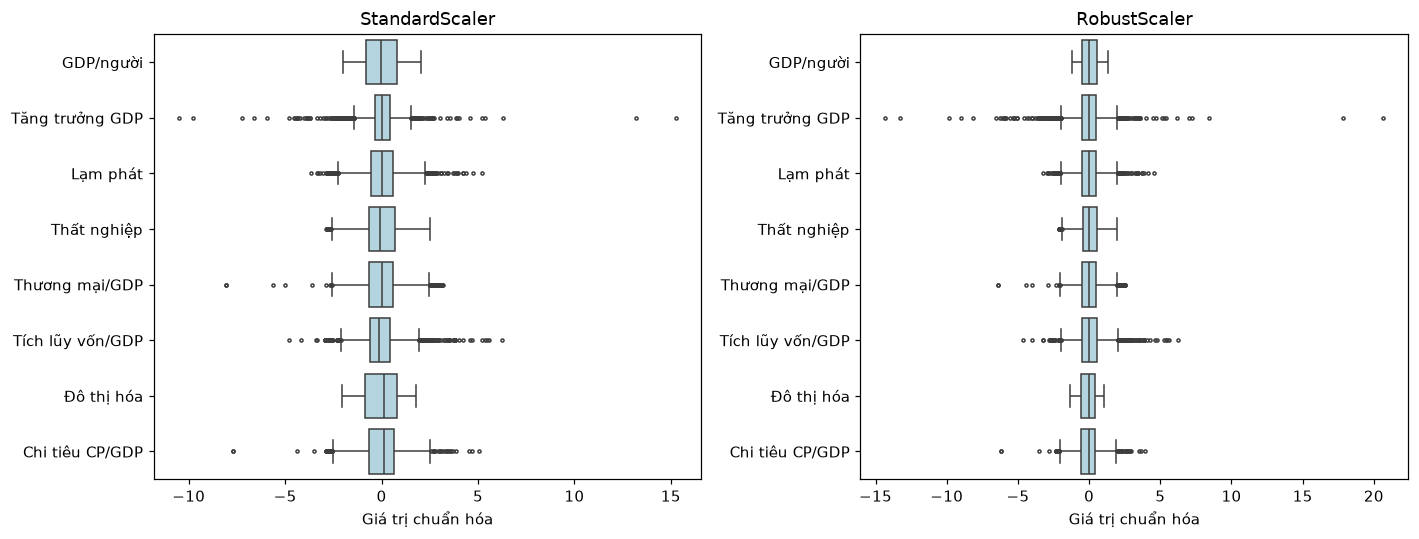

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
standard = pd.DataFrame(StandardScaler().fit_transform(transformed), columns=features)
robust = pd.DataFrame(values, columns=features)
for ax, frame, title in zip(axes, [standard, robust], ["StandardScaler", "RobustScaler"]):
    sns.boxplot(data=frame.rename(columns=names), orient="h", ax=ax, color="lightblue", fliersize=2)
    ax.set(title=title, xlabel="Giá trị chuẩn hóa")
fig.tight_layout(); fig.savefig(FIG / "06_so_sanh_truoc_va_sau_chuan_hoa.png"); plt.show()

## 9. Xuất dữ liệu đầu vào cho DBSCAN

In [12]:
clean_path = CLEAN / "wdi_clean.csv"
scaled_path = SCALED / "wdi_scaled.csv"
clean.to_csv(clean_path, index=False, lineterminator="\n")
scaled.to_csv(scaled_path, index=False, lineterminator="\n")
imputation_log.to_csv(CLEAN / "nhat_ky_noi_suy.csv", index=False, lineterminator="\n")
metadata = {
    "dataset": "World Bank WDI", "source_id": 2, "snapshot_access_date": manifest["access_date"],
    "study_years": [int(clean.year.min()), int(clean.year.max())],
    "key_columns": KEYS, "feature_columns": features,
    "study_scope": {"mode": "global_panel", "samples_per_year": clean.groupby("year").size().to_dict()},
    "missing_value_policy": {"internal_max_gap": 2, "boundary_max_gap": 1,
                             "remaining_missing": "drop rows", "filled_cells": len(imputation_log)},
    "transformations": {"log1p_columns": log_columns, "signed_log1p_columns": signed_columns,
                        "identity_columns": [f for f in features if f not in log_columns + signed_columns]},
    "scaling": {"scaler": "RobustScaler", "fit_scope": "global_panel", "quantile_range": [25, 75],
                "center_median": dict(zip(features, scaler.center_)), "scale_iqr": dict(zip(features, scaler.scale_))},
    "outputs": {"clean_rows": len(clean), "scaled_rows": len(scaled),
                "clean_sha256": hashlib.sha256(clean_path.read_bytes()).hexdigest(),
                "scaled_sha256": hashlib.sha256(scaled_path.read_bytes()).hexdigest()},
}
(SCALED / "preprocessing_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
assert clean[KEYS].equals(scaled[KEYS])
print("Đã xuất dữ liệu sạch, chuẩn hóa, nhật ký nội suy và metadata.")

Đã xuất dữ liệu sạch, chuẩn hóa, nhật ký nội suy và metadata.


## 10. Kết luận và bàn giao dữ liệu

In [13]:
summary = pd.DataFrame({"stage": ["Gốc", "Không tổng hợp", "Đủ biến trước nội suy", "Bàn giao"],
                        "rows": [len(raw), len(source), len(source.dropna(subset=features)), len(clean)]})
display(summary)
print(f"Việt Nam: {clean.country.eq('VNM').sum()} năm; không loại ngoại lệ theo IQR.")

,stage,rows
0,Gốc,3990
1,Không tổng hợp,3255
2,Đủ biến trước nội suy,2310
3,Bàn giao,2315


Việt Nam: 15 năm; không loại ngoại lệ theo IQR.
